# Player styles, passing performance and scouting candidates
## What this first test found
**A useful comparison prototype is possible. Fixed archetypes, an intrinsic player-quality rating and successful replacements are not established.**

Two broad style groups separate relative backfield activity from activity farther upfield. Two groups separate more clearly than three through six in both reference seasons. In the 2026 check, 126 of 146 players (86.3%) stayed in the same group between season halves, but chance-adjusted stability was 0.524, below our pilot threshold of 0.60. The 2025 replication also missed this threshold. This is evidence of broad structure, not proof of immutable player types or evidence that no useful archetypes exist.

Adding prior-year player passing-performance offsets to a geometry + prior-team model improved later Brier error by only 0.058% in 2025 and worsened it by 0.020% in 2026. Both game- and player-bootstrap intervals include no improvement. This model has not earned use as a transferable quality rating. It does not show that player skill is unimportant.

The website provides 230 qualifying 2026 player profiles, their five closest style matches, and separate recorded outcome comparisons. A similar style is a reason to scout someone, not a finding that the player is a successful replacement.

## Source, population and reproducibility
The source is the preserved October 12, 2026 export of prod.throws, prod.games, prod.players and prod.teams. This is not a fresh live query. SHA-256 hashes are checked against the import manifest. Non-stall throws require usable field endpoints; catches require completion and a named receiver. Attack direction is normalized toward Y=120. Unnamed throwers do not enter throwing profiles. One Pittsburgh regular-season game lacks throws.

Annual profiles require at least 100 throws AND 100 completed catches, at least six games in each role, and a single team per player-season. This high-involvement cohort excludes many specialist and low-minute roles. The temporal test requires 50 throws/catches and three games in each role in both halves of the evaluation season. Half-season splits use actual game timestamps; a rescheduled 2025 game is ordered by its actual date.

The executed notebook reads the saved full analysis and re-runs independent data/numerical checks. Set RECOMPUTE=True below to regenerate the clustering, reference simulations, bootstrap intervals and performance models from the preserved CSVs. The main script is analysis/archetype_candidate_validation.py; all modeling code and fixed seeds are saved locally. These are exploratory tests on seasons examined in earlier research, not a preregistered external validation.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'analysis/archetype_candidate_validation.py').exists())
sys.path.insert(0, str(ROOT/'analysis'))
RECOMPUTE = False
if RECOMPUTE:
    from archetype_candidate_validation import run
    result = run()
else:
    result = json.loads((ROOT/'analysis/archetype_candidate_validation.json').read_text())
print('Saved analysis:', result['analyzedAt'])
print('Source export:', result['sourceSnapshot'], '| Displayed profiles:', len(result['profiles']))

Saved analysis: 2026-10-26T22:53:18.885950+00:00
Source export: 2026-10-12 | Displayed profiles: 230


In [2]:
from archetype_candidate_checks import check
check()

PASS: four source hashes; all 230 annual profiles independently reconciled; clustering/offset numerical fixtures; temporal membership, model dates and Brier arithmetic.


## 1. Are there fixed archetypes?
Nine outcome-free traits are standardized using the reference year only. Four groups get equal weight: passing choices, throwing locations, completed-catch locations and disc involvement. K-means uses 20 starts, K=2–6, and minimum cluster size max(12, 5% of reference players). We select the smallest K within 0.02 of the best admissible silhouette.

We compare the separation with 100 correlated Gaussian reference datasets and refit 60 whole-team bootstraps. The Gaussian comparison is an explicit unimodal reference assumption; it is not distribution-free proof of natural categories. Selected K is reselected in each reference dataset, with five starts per candidate.

Pilot gates: Gaussian upper-tail fraction <0.05, median bootstrap adjusted Rand index ≥0.80, and later half-season adjusted Rand index ≥0.60. These are chosen screening criteria, not universal definitions. Adjusted Rand index equals 1 for identical partitions and averages about 0 for chance agreement. Group labels are arbitrary, and the score accounts for their permutation. Neither validation year passes all gates, specifically because temporal stability misses the chosen cutoff.

In [3]:
cluster_table = pd.DataFrame([{
    'Reference → test': f"{s['referenceSeason']} → {s['testSeason']}",
    'Reference players': s['referencePlayers'], 'Later paired players': s['evaluatedHalfSeasonPlayers'],
    'Selected K': s['selectedK'], 'Silhouette': round(s['selectedSilhouette'],3),
    'Gaussian tail': round(s['gaussianReferenceTailFraction'],4),
    'Median refit ARI': round(s['bootstrapARI']['median'],3),
    'Stayed in group (%)': round(s['heldoutSameGroupRate']*100,1),
    'Later ARI': round(s['heldoutARI'],3), 'Passes all pilot gates': s['passedPilotGates']
} for s in result['clusterStudies']])
cluster_table

,Reference → test,Reference players,Later paired players,Selected K,Silhouette,Gaussian tail,Median refit ARI,Stayed in group (%),Later ARI,Passes all pilot gates
0,2024 → 2025,254,138,2,0.351,0.0099,0.907,87.0,0.543,False
1,2025 → 2026,227,146,2,0.350,0.0099,0.913,86.3,0.524,False


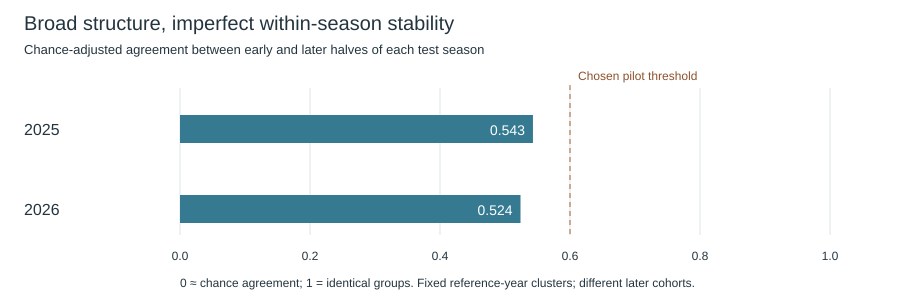

In [4]:
class Figure:
    def __init__(self,svg): self.svg=svg
    def _repr_svg_(self): return self.svg
    def __repr__(self): return 'Embedded SVG research figure'

svg=['<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 920 300" role="img" aria-label="Later group stability misses the 0.60 pilot threshold in both years">',
     '<rect width="920" height="300" fill="white"/><g font-family="Arial" fill="#24343e">',
     '<text x="24" y="30" font-size="20">Broad structure, imperfect within-season stability</text>',
     '<text x="24" y="54" font-size="13">Chance-adjusted agreement between early and later halves of each test season</text>']
x=lambda v:180+650*v
for v in [0,.2,.4,.6,.8,1]:
    svg.append(f'<line x1="{x(v)}" x2="{x(v)}" y1="88" y2="235" stroke="#e0e5e8"/><text x="{x(v)}" y="260" text-anchor="middle" font-size="12">{v:.1f}</text>')
for i,s in enumerate(result['clusterStudies']):
    y=115+i*80; v=s['heldoutARI']
    svg.append(f'<text x="24" y="{y+20}" font-size="16">{s["testSeason"]}</text><rect x="180" y="{y}" width="{650*v}" height="28" fill="#367a91"/><text x="{x(v)-8}" y="{y+20}" text-anchor="end" fill="white" font-size="14">{v:.3f}</text>')
svg.append(f'<line x1="{x(.6)}" x2="{x(.6)}" y1="85" y2="235" stroke="#a76236" stroke-dasharray="5 4"/><text x="{x(.6)+8}" y="80" font-size="12" fill="#8d512d">Chosen pilot threshold</text>')
svg.append('<text x="180" y="287" font-size="12">0 ≈ chance agreement; 1 = identical groups. Fixed reference-year clusters; different later cohorts.</text></g></svg>')
Figure(''.join(svg))

In [5]:
centers = sorted(result['clusterStudies'][-1]['groupCentroids'],key=lambda r:r['releaseY'])
pd.DataFrame([{'Exploratory family': label, '2025 players': r['trainingPlayers'],
    'Mean throwing Y (yd)': round(r['releaseY'],1), 'Mean catching Y (yd)': round(r['catchY'],1),
    'Huck share (%)': round(r['huckShare']*100,1), 'Short-pass share (%)': round(r['shortShare']*100,1),
    'Throws / involvements (%)': round(r['throwShare']*100,1)}
    for label,r in zip(['Relatively backfield','Farther upfield'],centers)])

,Exploratory family,2025 players,Mean throwing Y (yd),Mean catching Y (yd),Huck share (%),Short-pass share (%),Throws / involvements (%)
0,Relatively backfield,117,45.0,51.3,4.7,22.2,54.7
1,Farther upfield,110,56.5,62.2,5.0,25.4,48.5


These are averages of player profiles, not pooled event rates. The two families have nearly the same huck share (4.7% versus 5.0%). Calling these “deep thrower” versus “short-pass player” would misrepresent what this model found. Mean throwing position differs by about 11.5 yards. Splitting into more clusters reduced silhouette in both reference years; detailed coach-defined archetypes remain an open hypothesis.

## 2. Does prior passing performance improve later predictions?
The baseline adjusts for coarse throw distance, forward gain, throwing Y, sidelines and end-zone targets. Geometry uses recorded endpoints retrospectively, not receiver position available to the thrower before release. For each evaluation season, the geometry model is trained strictly on earlier seasons. Team and player offsets are fitted using only the immediately preceding year; a still-earlier geometry model supplies that year's expected probabilities. Offsets use a fixed ridge precision of 5.

Evaluation compares geometry + prior team + prior player with geometry + prior team, on test-season throws by players with at least 100 prior-year throws. This isolates the increment from the player offset. Brier error is the mean squared difference between predicted probability and actual completion; lower is better. Whole games and, separately, whole players are resampled 5,000 times. These uncertainty calculations hold the fitted models fixed. Neither test isolates intrinsic ability from teammates, strategy, opponents, wind or defensive pressure.

In [6]:
performance=[]
for s in result['outcomeStudies']:
    c=s['comparisons']; scale=100/c['baselineBrier']
    performance.append({'Test season':s['testSeason'],'Throws':s['evaluatedThrows'],'Players':s['evaluatedPlayers'],
        'Baseline Brier':c['baselineBrier'],'With player Brier':c['playerBrier'],
        'Relative improvement (%)':c['relativeBrierImprovementPct'],
        'Game 95% low (%)':c['gameBootstrap']['ci95'][0]*scale,
        'Game 95% high (%)':c['gameBootstrap']['ci95'][1]*scale,
        'Player 95% low (%)':c['playerBootstrap']['ci95'][0]*scale,
        'Player 95% high (%)':c['playerBootstrap']['ci95'][1]*scale})
pd.DataFrame(performance).round(5)

,Test season,Throws,Players,Baseline Brier,With player Brier,Relative improvement (%),Game 95% low (%),Game 95% high (%),Player 95% low (%),Player 95% high (%)
0,2025,39426,212,0.05341,0.05338,0.05791,-0.18175,0.30455,-0.18608,0.31896
1,2026,34571,186,0.04866,0.04867,-0.02001,-0.32355,0.27913,-0.45708,0.39511


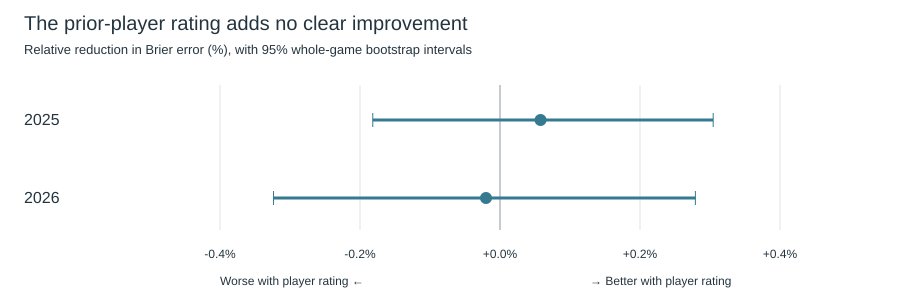

In [7]:
svg=['<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 920 300" role="img" aria-label="Passing performance adds approximately zero prediction improvement in 2025 and 2026">',
     '<rect width="920" height="300" fill="white"/><g font-family="Arial" fill="#24343e">',
     '<text x="24" y="30" font-size="20">The prior-player rating adds no clear improvement</text>',
     '<text x="24" y="54" font-size="13">Relative reduction in Brier error (%), with 95% whole-game bootstrap intervals</text>']
x=lambda v:500+700*v
for v in [-.4,-.2,0,.2,.4]:
    svg.append(f'<line x1="{x(v)}" x2="{x(v)}" y1="85" y2="230" stroke="{"#8c979e" if v==0 else "#e0e5e8"}"/><text x="{x(v)}" y="258" text-anchor="middle" font-size="12">{v:+.1f}%</text>')
for i,r in enumerate(performance):
    y=120+i*78; lo=x(r['Game 95% low (%)']);hi=x(r['Game 95% high (%)']);point=x(r['Relative improvement (%)'])
    svg.append(f'<text x="24" y="{y+5}" font-size="16">{r["Test season"]}</text><line x1="{lo}" x2="{hi}" y1="{y}" y2="{y}" stroke="#367a91" stroke-width="3"/><line x1="{lo}" x2="{lo}" y1="{y-7}" y2="{y+7}" stroke="#367a91"/><line x1="{hi}" x2="{hi}" y1="{y-7}" y2="{y+7}" stroke="#367a91"/><circle cx="{point}" cy="{y}" r="6" fill="#367a91"/>')
svg.append('<text x="220" y="285" font-size="12">Worse with player rating ←</text><text x="590" y="285" font-size="12">→ Better with player rating</text></g></svg>')
Figure(''.join(svg))

The website's “versus geometry expectation” values are 2026 observed completion minus this research model's geometry expectation, with per-player game-bootstrap intervals. They are separate from the prior-year offsets tested above, and are not Shown Space CPOE. A positive observed value is not proof it will persist next season. Do not promote this to a recruiting-quality leaderboard on the strength of these tests.

## 3. Who plays similarly enough to scout?
Candidates are ranked by weighted Euclidean distance across the nine style traits. Each group has total weight 25%; scale is the fixed standard deviation of 227 qualified 2025 profiles. Current 2026 candidate profiles are compared retrospectively. Other-team candidates are the default. Team, player name, absolute volume and passing outcomes are excluded from the distance. Lower is more similar; the distance is not a probability or success score.

In [8]:
profiles=pd.DataFrame(result['profiles']).set_index('id')
reference=result['clusterStudies'][-1]
selected=profiles.loc['aatkins']
features=list(result['features'])
distance=np.sqrt(sum(reference['weights'][f]*((profiles[f]-selected[f])/reference['scalerSD'][f])**2 for f in features))
peers=profiles[profiles.team.ne(selected.team)].assign(styleDistance=distance).sort_values(['styleDistance','name']).head(5)
table=pd.concat([profiles.loc[['aatkins']].assign(styleDistance=0),peers])
table[['name','teamName','throws','catches','styleDistance','huckAttempts','huckCompletions','completionRate']].round(4)

,name,teamName,throws,catches,styleDistance,huckAttempts,huckCompletions,completionRate
id,,,,,,,,
aatkins,Alex Atkins,New York Empire,432,364,0.0000,35,28,0.9699
hgoldenbe,Henry Goldenberg,Chicago Union,226,187,0.3717,16,7,0.9159
jkerr,Jordan Kerr,Salt Lake Shred,383,324,0.4357,19,14,0.9582
jnissen,Jacques Nissen,DC Breeze,418,317,0.4743,18,13,0.9545
alearned,Aylen Learned,Colorado Apex,210,171,0.5217,15,5,0.9095
ataylor,Austin Taylor,Atlanta Hustle,556,487,0.5369,34,27,0.9568


Alex Atkins's closest measured cross-team match is Henry Goldenberg. Their recorded regular-season huck results are 28/35 (80.0%) and 7/16 (43.8%), respectively. Goldenberg's sample is small, and the throws do not have identical difficulty or context. This is a concrete reason to separate similar style from equal observed performance and successful replacement.

**Coaching use now:** identify plausible role comparisons, inspect where their tendencies differ, compare actual sample sizes/outcomes, and select film to review. A candidate with matching locations and pass choices may still be unsuitable because of defensive ability, movement, availability or roster constraints.

**Next useful research step:** ask a coach to define a small set of offensive roles with observable criteria and label a blinded player sample; test whether those role assignments can be reproduced in later games. Evaluate recruitment value only when a defined lineup role and an outcome after substitution or transfer are available. The seven qualifying cross-team movers in the earlier year-over-year study are too few for a reliable replacement-success claim.

Methods reference: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation (definitions and assumptions for silhouette and adjusted Rand index; computations here use saved NumPy implementations, not an installed scikit-learn package).